# United Kingdom Measles and MMR Vaccine Tracking Dashboard

This dashboard analyzes public health data from the United Kingdom Health Security Agency (UKHSA), specifically exploring measles cases and MMR vaccination coverage percentages in England over several years.

--------

In [ ]:
from IPython.display import clear_output
from IPython.display import display
import ipywidgets as wdg
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from html import escape
import requests
import time
import json

%matplotlib inline
# make figures larger
plt.rcParams['figure.dpi'] = 100

%matplotlib widget
import mplcursors

In [2]:
# Load JSON files and store the raw data in a variable as a dictionary

with open("measles_cases.json", "rt") as INFILE:
    cases_jsondata = {"measles_cases": json.load(INFILE)}
with open("mmr1_coverage.json", "rt") as INFILE:
    mmr1_jsondata = {"mmr1_coverage": json.load(INFILE)} 
with open("mmr2_coverage.json", "rt") as INFILE:
    mmr2_jsondata = {"mmr2_coverage": json.load(INFILE)}

In [3]:
# Below function wrangles the raw data from the JSON file cases_jsondata into a DataFrame that will be used for plotting measles cases per week

def wrangle_date_measles_cases(measles_cases):
    """ Parameters: measles_cases - data from json file. Returns a DataFrame.
    Includes the code that wrangles the data, creates the DataFrame, and fills it in. """
   
    # Measles cases by week onset metric, metric value, and date
    data = {}
    for dataset in [measles_cases]:
        for entry in dataset:
            date = entry['date']
            metric = entry['metric']
            value = entry['metric_value']
            if date not in data:
                data[date] = {}
            data[date][metric] = value
     
     # Parse and sort dates
    dates = sorted(data.keys())
    startdate = pd.to_datetime(dates[0])
    enddate = pd.to_datetime(dates[-1])
   
    # Create the DataFrame
    index = pd.date_range(startdate, enddate, freq='W-MON')
    df = pd.DataFrame(index = index, columns = ['Cases'])
    
    # Insert the data into the DataFrame
    metrics = {'Cases': 'measles_cases_casesByOnsetWeek'}
    for date, entry in data.items(): 
        pd_date = pd.to_datetime(date) 
        for column in ['Cases']: 
            metric_name = metrics[column]
            value = entry.get(metric_name, 0.0)
            df.loc[date, column] = value
    df.fillna(0.0, inplace = True)
    return df

cdf = wrangle_date_measles_cases(cases_jsondata["measles_cases"]) # cdf is the DataFrame for plotting

In [4]:
# Below function wrangles the raw data from the JSON file cases_jsondata into a DataFrame that will be used for plotting measles cases by age group

def wrangle_data_measles_age(measles_cases):
    """ Parameters: measles_cases - data from json file. Returns a DataFrame.
    Includes the code that wrangles the data, creates the DataFrame and fills it in. """    
    
    # Measles cases by week onset metric value, date, and age
    data = {}
    for entry in measles_cases:
        date = entry['date']
        age = entry['age'] # Collecting age as the 'metric'
        value = entry['metric_value'] # Still collecting the actual metric (measles cases)
        if age == 'all': # Skips 'all' entry for age since not valuable metric to ages data
            continue
        if date not in data:
            data[date] = {}
        data[date][age] = value
    
    # Parse and sort dates
    dates = sorted(data.keys())
    startdate = pd.to_datetime(dates[0])
    enddate = pd.to_datetime(dates[-1])
    
    # Parse and sort age
    ages = []
    for entry in data.values():
        for age in entry.keys():
            if age not in ages:
                ages.append(age)
    ages.sort()
    
    # Create the DataFrame
    index = pd.date_range(startdate, enddate, freq = 'W-MON') # W-MON "weekly on Mondays" (when data is updated)
    df = pd.DataFrame(index = index, columns=ages)
   
   # Insert the data into the DataFrame
    for date, entry in data.items(): # Each entry is a dictionary with some ages and values
        pd_date = pd.to_datetime(date) 
        for column in entry.keys(): # The ages
            df.loc[pd_date, column] = entry[column] #.loc to access a specific location in the DataFrame
    df.fillna(0.0, inplace = True) # Filling in any remaining "holes" due to missing dates and ages
    df.infer_objects(copy = False) # Adjust types of columns filled in                
    return df

adf = wrangle_data_measles_age(cases_jsondata["measles_cases"]) # adf is the DataFrame for plotting

/var/folders/7r/9639fjfd1h741w8n5fzfkf5w0000gn/T/ipykernel_63182/1398966293.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(0.0, inplace = True) # Filling in any remaining "holes" due to missing dates and ages


In [5]:
# Below function wrangles the raw data from the JSON files mmr1_jsondata and mmr2_jsondata into a DataFrame that will be used for plotting mmr vaccination percentages

def wrangle_data_mmr(mmr1_coverage, mmr2_coverage):
    """ Parameters: mmr1_coverage, mmr2_coverage - data from json file. Returns a DataFrame.
    Includes the code that wrangles the data, creates the DataFrame and fills it in. """
    
    # MMR1 & MMR2 coverage percentages metric value, metric, and date
    data = {}
    for entry in mmr1_coverage:  
        date = entry['date']
        metric = entry['metric']
        value = entry['metric_value']
        if date not in data:
            data[date] = {}
        data[date][metric] = value
    for entry in mmr2_coverage: 
        date = entry['date']
        metric = entry['metric']
        value = entry['metric_value']
        if date not in data:
            data[date] = {}
        data[date][metric] = value
    
    # Parse and sort dates
    dates = sorted(data.keys())
    startdate = pd.to_datetime(dates[0])
    enddate = pd.to_datetime(dates[-1])
    
    # Create the DataFrame
    index = pd.date_range(startdate, enddate, freq = 'YE-MAR') # Yearly repeating in March 
    df = pd.DataFrame(index = index, columns = ['MMR1', 'MMR2'])
    
    # Translate the columns to the metrics and inserting the data into DataFrame
    metrics = {'MMR1': 'MMR1_coverage_coverageByYear', 'MMR2': 'MMR2_coverage_coverageByYear'}
    for date, entry in data.items(): 
        pd_date = pd.to_datetime(date) 
        for column in ['MMR1', 'MMR2']: 
            metric_name = metrics[column]
            value = entry.get(metric_name, 0.0)
            df.loc[date, column] = value
    df.fillna(0.0, inplace = True)
    return df

df = wrangle_data_mmr(mmr1_jsondata["mmr1_coverage"], mmr2_jsondata["mmr2_coverage"]) # df is the DataFrame for plotting

## Refresh the Data

UKHSA data update trends: 
- Measles case data - updated once a week on Mondays
- MMR vaccination coverage data - updated once a year in March

The button below refreshes the data to the current collected data. After the data has successfully refreshed, the button will turn green. The user will see the updated data in the Graphs and Analysis section.

If the server cannot be reached, the refresh button will turn red and display "Unavailable". The graphs will be loaded from stored data, and the user can try again later.

In [6]:
# Below functions download the current data to give the user an option to refresh the dataset in conjunction with the refresh button

# Uses APIwrapper which is imported from a separate file
from APIwrapper import APIwrapper

def access_api_measles(): # Access API data from UKHSA for measles cases
    """ Accesses the UKHSA API for measles cases. Returns data as a like-for-like 
    replacement for the "canned" data loaded from the JSON file. """
    api = APIwrapper(theme = "infectious_disease", # Structure that contains the main parameters of the query  
                     sub_theme = "vaccine_preventable",
                     topic = "Measles",
                     geography_type = "Nation",
                     geography = "England", 
                     metric = "measles_cases_casesByOnsetWeek")
    measles_cases = api.get_all_pages()
    return measles_cases # Return data read from the API

def access_api_mmr1(): # Access API data from UKHSA for MMR1 percentages
    """ Accesses the UKHSA API for MMR1. Returns data as a like-for-like replacement 
    for the "canned" data loaded from the JSON file. """
    api = APIwrapper(theme = "immunisation", # Structure that contains the main parameters of the query  
                     sub_theme = "childhood-vaccines",
                     topic = "MMR1",
                     geography_type = "Nation",
                     geography = "England", 
                     metric = "MMR1_coverage_coverageByYear")
    mmr1_coverage = api.get_all_pages()
    return mmr1_coverage # Return data read from the API

def access_api_mmr2(): # Access API data from UKHSA for MMR2 percentages
    """ Accesses the UKHSA API for MMR2. Returns data as a like-for-like replacement 
    for the "canned" data loaded from the JSON file. """
    api = APIwrapper(theme = "immunisation", # Structure that contains the main parameters of the query  
                     sub_theme = "childhood-vaccines",
                     topic = "MMR2",
                     geography_type = "Nation",
                     geography = "England", 
                     metric = "MMR2_coverage_coverageByYear")
    mmr2_coverage = api.get_all_pages()
    return mmr2_coverage # Return data read from the API

In [ ]:
# Below function and widget set up a refresh button to refresh the API data for measles cases, MMR1 and MMR2

def api_button_callback(button):
    """ Button callback - takes the button as its parameter.
    Accesses API, wrangles data, updates global variable df and adf used for plotting. """
    
    # Get data from the API
    global cdf, adf, cases_jsondata, df, mmr1_jsondata, mmr2_jsondata
   
    # After click, button will look like the following
    button.icon = "spinner"
    button.description = "Refreshing..."
    button.disabled = True # User cannot click again
    try:
        # Access the API for measles cases, MMR1 and MMR2, assign to JSON files
        cases_jsondata["measles_cases"]=access_api_measles() 
        mmr1_jsondata["mmr1_coverage"]=access_api_mmr1()
        mmr2_jsondata["mmr2_coverage"]=access_api_mmr2()
        
        # Wrangle the data and overwrite the dataframe for plotting
        cdf = wrangle_date_measles_cases(cases_jsondata["measles_cases"]) 
        adf = wrangle_data_measles_age(cases_jsondata["measles_cases"]) 
        df = wrangle_data_mmr(mmr1_jsondata["mmr1_coverage"], mmr2_jsondata["mmr2_coverage"])
        
        # Refresh the widgets of the measles cases per week graph  
        year_cases.options = cdf.index.year.unique()
        year_cases.value = year_cases.options[-1]
        
        # Refresh the widgets of the measles cases by age group graph   
        year_age.options = adf.index.year.unique()
        year_age.value = year_age.options[-1]
        
        # Refresh the widgets of the MMR graph
        year_select_mmr.options = df.index.year.unique()
        old_start,old_end = year_select_mmr.index
        if old_start < year_select_mmr.options[0] or old_end > year_select_mmr.options[-1]:
            year_select_mmr.index = (0,len(year_select_mmr.options)-1)
        
        # If data refreshed, button will look like the following
        button.icon = "check"
        button.button_style = "success"
        button.tooltip = "Refresh successful"
        button.description = "Updated"
        button.disabled = True
    
    # If data refresh fails, button will look like the following
    except Exception as e:
        button.description = "Unavailable"
        button.button_style = "danger"
        button.tooltip = "Refresh failed"
        button.icon = "times"
        return

# Initial refresh button will look like the following
apibutton = wdg.Button(
    description = 'Refresh Data',
    disabled = False,
    button_style = 'info',
    tooltip = "Refresh UKHSA data for measles cases and MMR",
    icon = 'download'
)
apibutton.on_click(api_button_callback) # Name of function inside the brackets
display(apibutton)
# Run all cells before clicking on this button

Button(button_style='info', description='Refresh Data', icon='download', style=ButtonStyle(), tooltip='Refresh…

---------

## Graphs and Analysis

In [ ]:
# Functions for the hover and addresses duplication issue of graphs 

_figs = {}
_cursors = {}

def reset_fig(key):
    """ Call at the top of a graph cell so re-running it starts clean. """
    old = _cursors.pop(key, None)
    if old is not None:
        old.remove()
    fig = _figs.pop(key, None)
    if fig is not None:
        plt.close(fig)

def get_fig(key, **kwargs):
    """ Create the figure once; afterwards just wipe it and hand back a fresh axes. """
    fig = _figs.get(key)
    if fig is None:
        with plt.ioff(): # Stop automatic display of graph on creation 
            fig = plt.figure(**kwargs)
        fig.canvas.header_visible = False  # Remove "Figure" heading on the graphs
        fig.canvas.footer_visible = False # Remove the (x, y) coordinate at the bottom of the graphs
        fig.canvas.toolbar_visible = False # Remove the pan/zoom toolbar on the graphs
        _figs[key] = fig
    old = _cursors.pop(key, None) # Drop the previous hover cursor 
    if old is not None:
        old.remove()
    fig.clf()  # Clears axes, suptitle, legend
    ax = fig.add_subplot(111)
    return fig, ax

def add_hover(key, artists, text_func, accent='#167D9A'):
    """ Show a card while hovering. text_func(sel) returns the card text. """
    cursor = mplcursors.cursor(artists, hover=mplcursors.HoverMode.Transient)
    @cursor.connect("add")
    def _(sel):
        sel.annotation.set_text(text_func(sel))
        sel.annotation.set_fontsize(10)
        sel.annotation.get_bbox_patch().set(fc='white', ec=accent, alpha=1, boxstyle='round,pad=0.5')
        sel.annotation.arrow_patch.set(arrowstyle='-', color=accent, alpha=0.6)
    _cursors[key] = cursor
    return cursor

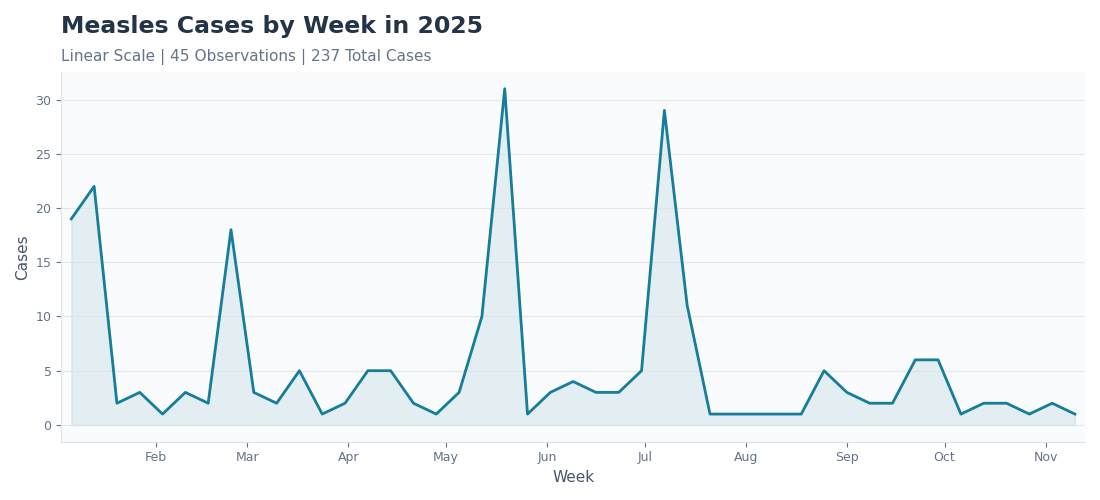

In [ ]:
# Year dropdown control
years = sorted(cdf.index.year.unique())
year_cases = wdg.Dropdown(
    options = years, 
    value = years[-1], 
    description = 'Year:', 
    style = {'description_width': 'initial'}, 
    layout = wdg.Layout(width = '220px'))

# Scale (linear/log) toggle control 
scale = wdg.ToggleButtons(
    options = ['Linear', 'Log'], 
    value = 'Linear', 
    description = 'Scale:', 
    style = {'description_width': 'initial'}, 
    layout = wdg.Layout(width = '280px'))

controls = wdg.HBox([year_cases, scale], layout = wdg.Layout(gap = '20px', align_items = 'center', margin = '0 0 15px 0'))

# Define the graph
def timeseries_graph(gyear, gscale):
    yeardf = cdf[cdf.index.year == gyear]
    if yeardf.empty:
        print("No data available for this year")
        return
    
    # Convert to numeric once and anything not numeric becomes NaN
    data = pd.to_numeric(yeardf.iloc[:, 0], errors = 'coerce').astype(float).sort_index()

    x = data.index
    y = data.to_numpy()

    valid = np.isfinite(y)
    if gscale == 'Log':
        valid &= (y > 0)  # Log scale can't show zero or negative values

    # Create the figure
    fig, ax = get_fig('cases', figsize=(11, 5))
    fig.patch.set_facecolor('white')
    ax.set_facecolor('#FAFBFC')

    # Plot weekly case counts. Plot once, using only valid points
    line, = ax.plot(x[valid], y[valid], color='#167D9A', linewidth=2, label='Weekly cases')

    # Add the hover
    add_hover('cases', line, lambda sel: (
        f"Week of {mdates.num2date(sel.target[0]):%d %b %Y}\n"
        f"{sel.target[1]:,.0f} Cases"))

    # Shade beneath the line
    if gscale == 'Log':
        ax.set_yscale('log')
        ax.fill_between(x, y, 1e-3, where=valid, color='#167D9A', alpha=0.10)
    else:
        ax.fill_between(x, y, 0, where=valid, color='#167D9A', alpha=0.10)

    # Titles and labels
    total = np.nansum(y)
    ax.set_title(f'Measles Cases by Week in {gyear}', loc='left', fontsize=17, fontweight='bold', color='#243447', pad=28)
    ax.text(0, 1.03, f'{gscale} Scale | {len(data)} Observations | {total:,.0f} Total Cases', transform=ax.transAxes, fontsize=11, color='#64748B')
    ax.set_xlabel('Week', fontsize=11, color='#475569')
    ax.set_ylabel('Cases', fontsize=11, color='#475569')

    # Date axis
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

    # Grid, borders, styling
    ax.grid(axis='y', color='#DCE3E8', linewidth=0.8, alpha=0.8)
    ax.grid(axis='x', visible=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#DCE3E8')
    ax.spines['bottom'].set_color('#DCE3E8')
    ax.tick_params(colors='#64748B', labelsize=9)
    ax.margins(x=0.01)
    fig.tight_layout()
    fig.canvas.draw_idle()

# Display the interactive chart
reset_fig('cases')
fig_cases, _ = get_fig('cases', figsize=(11, 5)) # Create it once

def redraw_cases(change=None):
    timeseries_graph(year_cases.value, scale.value)

year_cases.observe(redraw_cases, names='value')
scale.observe(redraw_cases, names='value')

redraw_cases()   # First draw
display(controls, fig_cases.canvas)  # Display it once

**Figure 1. Reported weekly measles cases in England.** Weekly laboratory confirmed measles cases reported by UKHSA displayed by year. Users can toggle between years and select a linear or logarithmic scale to compare weekly case trends. The most recent year is displayed by default.

**Key finding:** Reported measles cases peaked in 2024, reaching a maximum of 104 cases in May, while 2025 showed four notable peaks throughout the year. Although 2023 had the fewest reported cases (maximum of 13 in December) comparisons are limited due to the data only covering October-December.

Dropdown(description='Select year:', index=2, layout=Layout(width='250px'), options=(2023, 2024, 2025), style=…

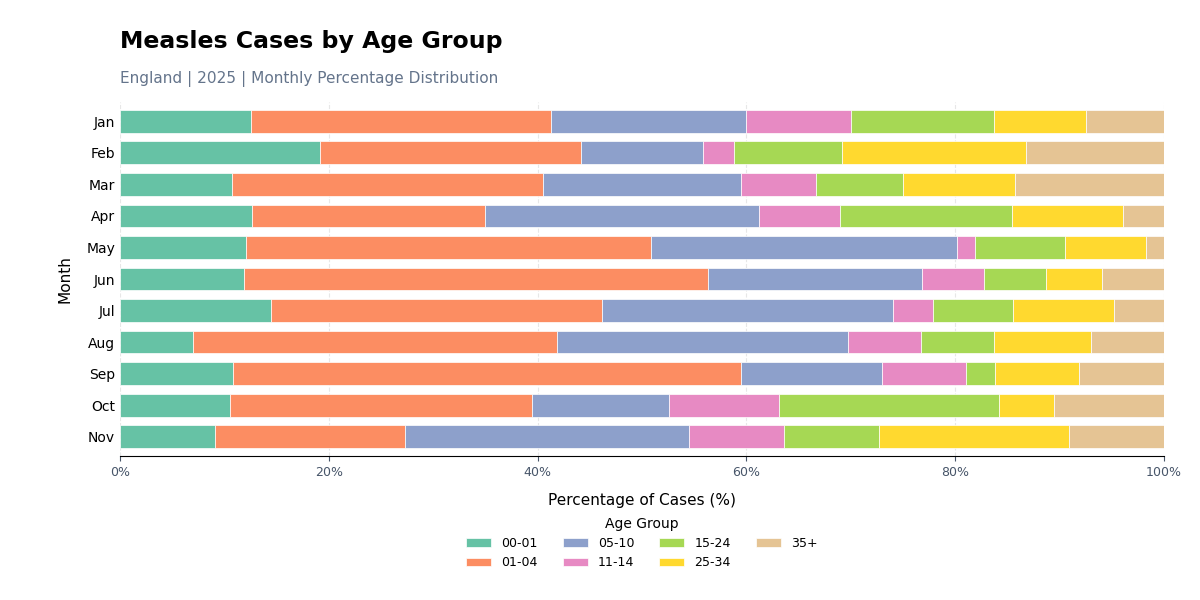

In [ ]:
# Year dropdown selector
years = sorted(adf.index.year.unique())
year_age = wdg.Dropdown(
    options=years, 
    value=years[-1], 
    description='Select year:', 
    style={'description_width': 'initial'}, 
    layout=wdg.Layout(width='250px'))

# Define the graph
def age_graph(graphyear):
    yeardf = adf[adf.index.year == graphyear]

    # Calculate monthly averages and percentage distribution
    monthly = yeardf.groupby(pd.Grouper(freq='1ME')).mean()
    totals = monthly.sum(axis=1)
    monthly = monthly.div(totals.replace(0, float('nan')), axis=0) * 100
    monthly = monthly[::-1]

    # Color palette
    colors = plt.cm.Set2.colors

    # Create the figure
    fig, ax = get_fig('age', figsize=(12, 6))
    monthly.plot(
        kind='barh', 
        stacked=True, 
        ax=ax, color=colors, 
        width=0.72, 
        edgecolor='white', 
        linewidth=0.5)
    
    # Part of the hover
    def age_text(sel):
        i = sel.index  # Which month
        bar = sel.artist[i] # The rectangle that was hit
        return (f"{monthly.index[i]:%B %Y}\n"
                f"{sel.artist.get_label()}: {bar.get_width():.1f}%")
    
    # Add the hover
    add_hover('age', ax.containers, age_text, accent='#676767')

    # Title and subtitle
    fig.suptitle(f'Measles Cases by Age Group', fontsize=17, fontweight='bold', x=0.10, ha='left', y=0.95)
    ax.set_title(f'England | {graphyear} | Monthly Percentage Distribution', fontsize=11, color='#64748b', loc='left', pad=14)

    # Axis formatting
    ax.set_xlabel('Percentage of Cases (%)', fontsize=11, labelpad=10)
    ax.set_ylabel('Month', fontsize=11, labelpad=10)
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_locator(mtick.MultipleLocator(20))
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    ax.set_yticks(range(len(monthly)))
    ax.set_yticklabels(monthly.index.strftime('%b'))

    # Grid, borders, styling
    ax.set_axisbelow(True)
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    ax.grid(axis='y', visible=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', length=0, labelsize=10)
    ax.tick_params(axis='x', labelsize=9, colors='#475569')

    # Compact legend beneath the chart
    ax.legend(title='Age Group', loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=4, frameon=False, fontsize=9, title_fontsize=10)
    fig.patch.set_facecolor('white')
    ax.set_facecolor('white')
    fig.subplots_adjust(left=0.10, right=0.97, top=0.83, bottom=0.24)
    fig.canvas.draw_idle()

# Display the interactive chart
reset_fig('age')
fig_age, _ = get_fig('age', figsize=(12, 6)) # Create it once

def redraw_ages(change=None):
    age_graph(year_age.value)

year_age.observe(redraw_ages, names='value')

redraw_ages()  # First draw
display(year_age, fig_age.canvas) # Display it once 

**Figure 2. Monthly distribution of measles cases by age group by in England, 2023-2025.** Monthly averages of UKHSA reported laboratory confirmed measles cases are expressed as percentages to compare the age distribution across months. The year dropdown can be used to explore different years with the most recent year selected by default. Data for 2023 is limited.

**Key finding:** Age groups 1-4 and 5-10 accounted for the largest proportions of average monthly cases across 2023-2025. Notable monthly changes occurred in these groups and in 15-24 and 35+ age groups during 2024-2025. Incomplete data for 2023 limits comparisons.

SelectionRangeSlider(continuous_update=False, description='Year range:', index=(0, 15), layout=Layout(width='6…

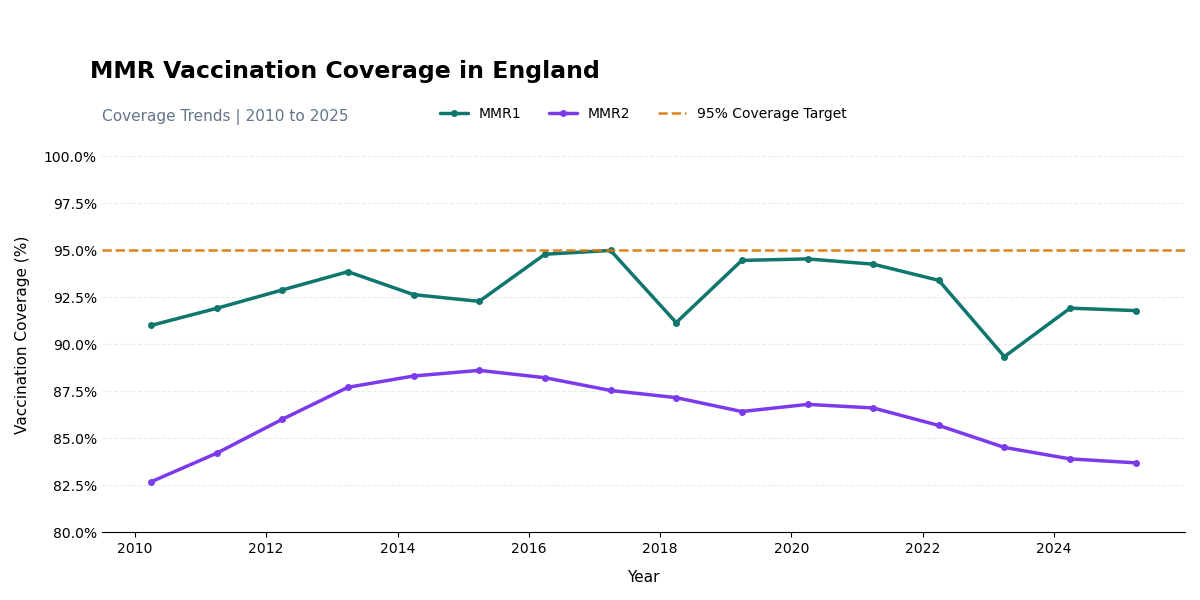

In [ ]:
# Year range slider
years_available = sorted(df.index.year.unique())
year_select_mmr = wdg.SelectionRangeSlider(
    options=years_available,
    index=(0, len(years_available) - 1),
    description='Year range:',
    disabled=False,
    continuous_update=False,
    layout=wdg.Layout(width='650px'),
    style={'description_width': 'initial'})

# Define the graph
def timeseries_graph_mmr(gyear):
    start, end = gyear
    years = pd.Series(df.index.year, index=df.index)
    yeardf = df.loc[years.between(start, end)]
    if yeardf.empty:
        return

    # Color palette
    colors = ['#0F766E', '#7C3AED']

    # Create the figure
    fig, ax = get_fig('mmr', figsize=(12, 6))

    # Plotting each vaccine series
    for i, column in enumerate(yeardf.columns):
        ax.plot(
            yeardf.index, 
            yeardf[column], 
            label=column, 
            color=colors[i % len(colors)],
            linewidth=2.5, 
            marker='o', 
            markersize=4, 
            markevery=max(1, len(yeardf) // 12), 
            solid_capstyle='round')

    # Capture all lines want hoverable besides the 95% reference line (put BEFORE axhline)
    mmr_lines = ax.get_lines()  

    # Title and subtitle
    fig.suptitle('MMR Vaccination Coverage in England', fontsize=17, fontweight='bold', x=0.075, ha='left', y=0.90)
    ax.set_title(f'Coverage Trends | {start} to {end}', fontsize=11, color='#64748B', loc='left', pad=12)

    # 95% reference line
    ax.axhline(y=95, color='#D97706', linestyle='--', linewidth=1.8, label='95% Coverage Target', alpha=0.9)

    # Add the hover
    add_hover('mmr', mmr_lines, lambda sel: (
        f"{sel.artist.get_label()}\n"
        f"{mdates.num2date(sel.target[0]):%b %Y}\n"
        f"Coverage: {sel.target[1]:.1f}%"), accent="#676767")

    # Axis formatting
    ax.set_xlabel('Year', fontsize=11, labelpad=10)
    ax.set_ylabel('Vaccination Coverage (%)', fontsize=11, labelpad=10)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
    ax.set_ylim(80, 101) # Focused y-axis 

    # Date labels
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    # Grid, borders, styling
    ax.set_facecolor('white')
    fig.patch.set_facecolor('white')
    ax.set_axisbelow(True)
    ax.grid(axis='y', linestyle='--', alpha=0.25)
    ax.grid(axis='x', visible=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='both', labelsize=10)
    ax.tick_params(axis='y', length=0)

    # Legend
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=3, frameon=False, fontsize=10)
    plt.tight_layout(rect=[0, 0, 1, 0.92])
    fig.canvas.draw_idle()

# Display the interactive chart
reset_fig('mmr')
fig_mmr, _ = get_fig('mmr', figsize=(12, 6)) # Create it once

def redraw_mmr(change=None):
    timeseries_graph_mmr(year_select_mmr.value)

year_select_mmr.observe(redraw_mmr, names='value')

redraw_mmr()  # First draw
display(year_select_mmr, fig_mmr.canvas)  # Display it once

**Figure 3. MMR1 and MMR2 vaccination coverage in England over time.** This line chart compares MMR1 coverage (first dose by 24 months and 5 years) and MMR2 coverage (second dose by 5 years). The date range slider can be used to explore different periods with the full available period shown by default. 

**Key finding:** MMR1 coverage was consistently higher than MMR2 coverage across the reported data. MMR1 peaked at 95% in 2017, while MMR2 peaked at 88.62% in 2015. The lowest recorded coverage was 89.35% for MMR1 in 2023 and 82.69% for MMR2 in 2010, highlighting a persistent gap between first- and second-dose coverage. 

In [ ]:
mmr2_column = 'MMR2'
target = 95

# Four KPI card widgets
kpi_cards = [
    wdg.HTML(),
    wdg.HTML(),
    wdg.HTML(),
    wdg.HTML()]

def make_card(title, value, subtitle, color):
    """Create one styled KPI card."""
    return f"""
    <div style="
        background: white;
        border: 1px solid #e2e8f0;
        border-top: 4px solid {color};
        border-radius: 15px;
        padding: 16px;
        min-height: 115px;
        box-sizing: border-box;
        font-family: Times, serif;
        text-align: center;
        box-shadow: 2px 4px 10px rgba(0,0,0,0.1);
">
        <div style="font-size: 15px; color: #64748b; font-family: Georgia, serif; margin-bottom: 10px;">
            {escape(str(title))}
        </div>
        <div style="font-size: 27px; font-weight: 700; color: #1e293b; margin-bottom: 7px;">
            {escape(str(value))}
        </div>
        <div style="font-size: 14px; color: #64748b; font-style: italic; font-weight: 400; letter-spacing: 0.3px;">
            {escape(str(subtitle))}
        </div>
    </div>
    """

def year_filter(frame, start, end):
    return frame.loc[(frame.index.year >= start) & (frame.index.year <= end)]

def update_kpis(change=None):
    case_year = year_cases.value # Graph 1
    age_year = year_age.value  # Graph 2
    mmr_start, mmr_end = year_select_mmr.value # Graph 3

    # KPI 1: Total cases (fig 1)
    cases = pd.to_numeric(year_filter(cdf, case_year, case_year).iloc[:, 0], errors='coerce')
    total_cases = cases.sum(min_count=1)
    cases_value = "N/A" if pd.isna(total_cases) else f"{total_cases:,.0f}"
    kpi_cards[0].value = make_card("TOTAL MEASLES CASES", cases_value, f"Year: {case_year}", "#0F766E")
    
    # KPI 2: Age group with the most cases (fig 2)
    measles = year_filter(adf, age_year, age_year).apply(pd.to_numeric, errors='coerce')
    age_totals = measles.sum(axis=0, min_count=1).dropna()
    if age_totals.empty:
        age_value, age_subtitle = "N/A", "No data available"
    else:
        age_value = str(age_totals.idxmax())
        share = age_totals.max() / age_totals.sum() * 100 if age_totals.sum() > 0 else float("nan")
        age_subtitle = f"{share:.1f}% of cases in {age_year}" if pd.notna(share) else "Share unavailable"
    kpi_cards[1].value = make_card("MOST AFFECTED AGE GROUP", age_value, age_subtitle, "#D97706")
    
    # KPI 3: Latest MMR2 coverage in the selected range (fig 3)
    mmr = year_filter(df, mmr_start, mmr_end).sort_index()
    coverage = mmr[mmr2_column].dropna() if mmr2_column in mmr.columns else pd.Series(dtype=float)
    if coverage.empty:
        latest_coverage, latest_date = float("nan"), "No observation"
    else:
        latest_coverage = coverage.iloc[-1]
        latest_date = coverage.index[-1].strftime("%b %Y")
    coverage_value = f"{latest_coverage:.1f}%" if pd.notna(latest_coverage) else "N/A"
    kpi_cards[2].value = make_card("LATEST MMR2 COVERAGE", coverage_value, f"Latest in {mmr_start}-{mmr_end}: {latest_date}", "#7C3AED")

    # KPI 4: Difference from the 95% reference target (fig 3)
    if pd.isna(latest_coverage):
        gap_value, gap_subtitle, gap_color = "N/A", "Coverage unavailable", "#64748b"
    else:
        gap = latest_coverage - target
        gap_value = f"{abs(gap):.1f} pp"
        gap_subtitle = (
            f"{abs(gap):.1f} percentage points "
            f"{'above' if gap > 0 else 'below' if gap < 0 else 'at'} the {target}% reference in {latest_date}")
        gap_color = "#0F766E" if gap >= 0 else "#DC2626"
    kpi_cards[3].value = make_card("MMR2 GAP TO TARGET", gap_value, gap_subtitle, gap_color)

# Arrange layout of cards
kpi_grid = wdg.GridBox(
    children = kpi_cards, 
    layout = wdg.Layout(width="100%", grid_template_columns="repeat(2, minmax(0, 1fr))", grid_gap="12px"))

# Update when any graph's date control changes
for w in (year_cases, year_age, year_select_mmr):
    w.observe(update_kpis, names="value")

# Initial calculation and display
update_kpis()
display(kpi_grid)

GridBox(children=(HTML(value='\n    <div style="\n        background: white;\n        border: 1px solid #e2e8f…

## Summary

The downward trend of MMR2 coverage percentages from 2023-2025 could signify children are not receiving the second MMR dose by the age of 5 which is required to reach full protection against measles. Subsequently, children aged 1-10 years have higher measles susceptibility attributing to the higher average monthly measles case data. The data suggests that declining or insufficient MMR vaccination coverage, particularly completion of the second dose, may be contributing to increased and recurrent measles outbreaks, with the greatest impact on young children. Strengthening vaccine uptake is a critical step to reducing future measles transmission.

---------

U.K. Measles and MMR Vaccine Tracking Dashboard (C) Shyanne Herman, 2025. Based on UK Government [data](https://ukhsa-dashboard.data.gov.uk/) published by the [UK Health Security Agency](https://www.gov.uk/government/organisations/uk-health-security-agency) and on the [DIY Disease Tracking Dashboard Kit](https://github.com/fsmeraldi/diy-covid19dash) by Fabrizio Smeraldi. Released under the [GNU GPLv3.0 or later](https://www.gnu.org/licenses/).